# <font color='blue'>Projeto 2 - PARTE 2</font>
# <font color='blue'>Predição do Número de Estudantes Desvinculados em Cursos de Graduação no Brasil Utilizando Técnicas de Machine Learning</font>

In [86]:
import warnings

import joblib
import gc
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

warnings.filterwarnings("ignore")

In [2]:
# !pip install -q -U watermark

In [3]:
# Versões dos pacotes usados neste jupyter notebook
%reload_ext watermark
%watermark -a "Mauricio Vinhote"

Author: Mauricio Vinhote



## 1. Carregando os dados

Iniciamos carregando os dados que já foram processados na parte 3 do projeto e fazemos uma rápida verificação a fim de certificar-nos de que não há problemas com os dados.

In [4]:
dados_preparados = pd.read_csv(
    r"C:\Users\mvinh\3_PROJETOS\dados_preparados.csv",
    sep=',',
    encoding="latin1"
)

In [5]:
dados_preparados.head()

,NU_ANO_CENSO,QT_SIT_DESVINCULADO,QT_ING,QT_MAT,QT_CONC,QT_SIT_TRANCADA,QT_SIT_TRANSFERIDO,QT_SIT_FALECIDO,QT_APOIO_SOCIAL,QT_ATIV_EXTRACURRICULAR,...,QT_MAT_LOG,CO_UF,CO_REGIAO,IN_CAPITAL,TP_CATEGORIA_ADMINISTRATIVA,TP_MODALIDADE_ENSINO,TP_ORGANIZACAO_ACADEMICA,TP_GRAU_ACADEMICO,CO_CINE_AREA_GERAL,CO_CINE_AREA_ESPECIFICA
0,2009,0.0,44.0,44.0,0.0,0.0,0.0,0.0,1.0,0.0,...,3.806662,11.0,1.0,0.0,1,1,1,1.0,7,72
1,2009,6.0,47.0,41.0,0.0,0.0,0.0,0.0,13.0,0.0,...,3.737670,11.0,1.0,0.0,1,1,1,2.0,1,11
2,2009,3.0,37.0,174.0,49.0,8.0,0.0,0.0,0.0,0.0,...,5.164786,11.0,1.0,0.0,6,1,3,1.0,4,41
3,2009,2.0,77.0,284.0,53.0,12.0,0.0,0.0,0.0,0.0,...,5.652489,11.0,1.0,0.0,6,1,3,1.0,4,41
4,2009,0.0,40.0,142.0,55.0,3.0,0.0,0.0,0.0,0.0,...,4.962845,11.0,1.0,0.0,6,1,3,2.0,1,11


Verificamos a existência de valores ausentes.

In [6]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

dados_preparados.isna().sum()

NU_ANO_CENSO                   0
QT_SIT_DESVINCULADO            0
QT_ING                         0
QT_MAT                         0
QT_CONC                        0
QT_SIT_TRANCADA                0
QT_SIT_TRANSFERIDO             0
QT_SIT_FALECIDO                0
QT_APOIO_SOCIAL                0
QT_ATIV_EXTRACURRICULAR        0
QT_SIT_FALECIDO_LOG            0
QT_SIT_TRANSFERIDO_LOG         0
QT_CONC_LOG                    0
QT_ATIV_EXTRACURRICULAR_LOG    0
QT_SIT_DESVINCULADO_LOG        0
QT_APOIO_SOCIAL_LOG            0
QT_SIT_TRANCADA_LOG            0
QT_ING_LOG                     0
QT_MAT_LOG                     0
CO_UF                          0
CO_REGIAO                      0
IN_CAPITAL                     0
TP_CATEGORIA_ADMINISTRATIVA    0
TP_MODALIDADE_ENSINO           0
TP_ORGANIZACAO_ACADEMICA       0
TP_GRAU_ACADEMICO              0
CO_CINE_AREA_GERAL             0
CO_CINE_AREA_ESPECIFICA        0
dtype: int64

In [7]:
dados_preparados.columns.to_list()

['NU_ANO_CENSO',
 'QT_SIT_DESVINCULADO',
 'QT_ING',
 'QT_MAT',
 'QT_CONC',
 'QT_SIT_TRANCADA',
 'QT_SIT_TRANSFERIDO',
 'QT_SIT_FALECIDO',
 'QT_APOIO_SOCIAL',
 'QT_ATIV_EXTRACURRICULAR',
 'QT_SIT_FALECIDO_LOG',
 'QT_SIT_TRANSFERIDO_LOG',
 'QT_CONC_LOG',
 'QT_ATIV_EXTRACURRICULAR_LOG',
 'QT_SIT_DESVINCULADO_LOG',
 'QT_APOIO_SOCIAL_LOG',
 'QT_SIT_TRANCADA_LOG',
 'QT_ING_LOG',
 'QT_MAT_LOG',
 'CO_UF',
 'CO_REGIAO',
 'IN_CAPITAL',
 'TP_CATEGORIA_ADMINISTRATIVA',
 'TP_MODALIDADE_ENSINO',
 'TP_ORGANIZACAO_ACADEMICA',
 'TP_GRAU_ACADEMICO',
 'CO_CINE_AREA_GERAL',
 'CO_CINE_AREA_ESPECIFICA']

## 2. Preparação dos dados para alimentar os algoritmos

Separamos a variável alvo das variáveis preditoras.

In [8]:
# Variável-alvo
y = dados_preparados['QT_SIT_DESVINCULADO'].copy()

In [10]:
X = dados_preparados.drop(columns='QT_SIT_DESVINCULADO').copy()

print('Variável-alvo:', 'QT_SIT_DESVINCULADO')
print('Número de preditores:', X.shape[1])

Variável-alvo: QT_SIT_DESVINCULADO
Número de preditores: 27


Definimos os conjuntos de treino e de teste.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [17]:
X.columns.to_list()

['NU_ANO_CENSO',
 'QT_ING',
 'QT_MAT',
 'QT_CONC',
 'QT_SIT_TRANCADA',
 'QT_SIT_TRANSFERIDO',
 'QT_SIT_FALECIDO',
 'QT_APOIO_SOCIAL',
 'QT_ATIV_EXTRACURRICULAR',
 'QT_SIT_FALECIDO_LOG',
 'QT_SIT_TRANSFERIDO_LOG',
 'QT_CONC_LOG',
 'QT_ATIV_EXTRACURRICULAR_LOG',
 'QT_SIT_DESVINCULADO_LOG',
 'QT_APOIO_SOCIAL_LOG',
 'QT_SIT_TRANCADA_LOG',
 'QT_ING_LOG',
 'QT_MAT_LOG',
 'CO_UF',
 'CO_REGIAO',
 'IN_CAPITAL',
 'TP_CATEGORIA_ADMINISTRATIVA',
 'TP_MODALIDADE_ENSINO',
 'TP_ORGANIZACAO_ACADEMICA',
 'TP_GRAU_ACADEMICO',
 'CO_CINE_AREA_GERAL',
 'CO_CINE_AREA_ESPECIFICA']

In [20]:
variaveis_numericas = [var for var in X.columns if var.startswith('QT') or var.startswith('NU')]

In [21]:
variaveis_numericas

['NU_ANO_CENSO',
 'QT_ING',
 'QT_MAT',
 'QT_CONC',
 'QT_SIT_TRANCADA',
 'QT_SIT_TRANSFERIDO',
 'QT_SIT_FALECIDO',
 'QT_APOIO_SOCIAL',
 'QT_ATIV_EXTRACURRICULAR',
 'QT_SIT_FALECIDO_LOG',
 'QT_SIT_TRANSFERIDO_LOG',
 'QT_CONC_LOG',
 'QT_ATIV_EXTRACURRICULAR_LOG',
 'QT_SIT_DESVINCULADO_LOG',
 'QT_APOIO_SOCIAL_LOG',
 'QT_SIT_TRANCADA_LOG',
 'QT_ING_LOG',
 'QT_MAT_LOG']

In [22]:
variaveis_categoricas = [var for var in X.columns if var.startswith(('CO','IN','TP'))]

In [23]:
variaveis_categoricas

['CO_UF',
 'CO_REGIAO',
 'IN_CAPITAL',
 'TP_CATEGORIA_ADMINISTRATIVA',
 'TP_MODALIDADE_ENSINO',
 'TP_ORGANIZACAO_ACADEMICA',
 'TP_GRAU_ACADEMICO',
 'CO_CINE_AREA_GERAL',
 'CO_CINE_AREA_ESPECIFICA']

O código a seguir aplica o OneHotEncoder e padroniza as variáveis numéricas.

In [25]:
preprocessador = ColumnTransformer(
    transformers=[
        (
            'categoricas',
            Pipeline([
                ('imputador', SimpleImputer(strategy='most_frequent')),
                ('encoder', OneHotEncoder(handle_unknown='ignore'))
            ]),
            variaveis_categoricas
        ),
        (
            'numericas',
            Pipeline([
                ('imputador', SimpleImputer(strategy='median')),
                ('escalonador', StandardScaler())
            ]),
            variaveis_numericas
        )
    ]
)

## 3. Versão 1 - versão vanilla com `ElasticNet` e dados SEM FILTRAGEM de valores grandes da variável alvo

In [30]:
modelo_v1 = Pipeline([
    ('preprocessador', preprocessador),
    ('regressor', ElasticNet(
        alpha=1.0,
        l1_ratio=0.5,
        max_iter=10000,
        random_state=42
    ))
])

In [31]:
modelo_v1.fit(X_train, y_train)

Pipeline(steps=[('preprocessador',
                 ColumnTransformer(transformers=[('categoricas',
                                                  Pipeline(steps=[('imputador',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['CO_UF', 'CO_REGIAO',
                                                   'IN_CAPITAL',
                                                   'TP_CATEGORIA_ADMINISTRATIVA',
                                                   'TP_MODALIDADE_ENSINO',
                                                   'TP_ORGANIZACAO_ACADEMICA',
                                                   'TP_GRAU_ACADEMICO',
                                                   'CO_CINE_ARE...
                                                   'QT_SIT_TRANCADA',
                                                   'QT_SIT_TRANSFERIDO',
                                                   'QT_SIT_FALECIDO',
                                                   'QT_APOIO_SOCIAL',
                                                   'QT_ATIV_EXTRACURRICULAR',
                                                   'QT_SIT_FALECIDO_LOG',
                                                   'QT_SIT_TRANSFERIDO_LOG',
                                                   'QT_CONC_LOG',
                                                   'QT_ATIV_EXTRACURRICULAR_LOG',
                                                   'QT_SIT_DESVINCULADO_LOG',
                                                   'QT_APOIO_SOCIAL_LOG',
                                                   'QT_SIT_TRANCADA_LOG',
                                                   'QT_ING_LOG',
                                                   'QT_MAT_LOG'])])),
                ('regressor', ElasticNet(max_iter=10000, random_state=42))])

In [33]:
# Previsões no conjunto de treino
y_pred_treino_v1 = modelo_v1.predict(X_train)

mae_treino = mean_absolute_error(y_train, y_pred_treino_v1)
rmse_treino = np.sqrt(mean_squared_error(y_train, y_pred_treino_v1))
r2_treino = r2_score(y_train, y_pred_treino_v1)

print('Métricas do ElasticNet no conjunto de treino')
print(f'MAE:  {mae_treino:.4f}')
print(f'RMSE: {rmse_treino:.4f}')
print(f'R²:   {r2_treino:.4f}')

# Previsões no conjunto de teste
y_pred_teste_v1 = modelo_v1.predict(X_test)

mae_teste = mean_absolute_error(y_test, y_pred_teste_v1)
rmse_teste = np.sqrt(mean_squared_error(y_test, y_pred_teste_v1))
r2_teste = r2_score(y_test, y_pred_teste_v1)

print('\nMétricas do ElasticNet no conjunto de teste')
print(f'MAE:  {mae_teste:.4f}')
print(f'RMSE: {rmse_teste:.4f}')
print(f'R²:   {r2_teste:.4f}')

Métricas do ElasticNet no conjunto de treino
MAE:  4.9916
RMSE: 21.1352
R²:   0.5946

Métricas do ElasticNet no conjunto de teste
MAE:  4.9639
RMSE: 19.0953
R²:   0.6311


**Análise das métricas do ElasticNet**

Os resultados obtidos pelo modelo ElasticNet indicam um desempenho preditivo consistente nos conjuntos de treino e teste. No conjunto de teste, o modelo apresentou MAE de 4,9639 estudantes, o que significa que o erro absoluto médio das previsões foi de aproximadamente cinco estudantes. O RMSE foi de 19,0953, consideravelmente superior ao MAE, sugerindo que algumas observações apresentam erros de previsão elevados, os quais exercem maior influência sobre essa métrica devido ao quadrado dos erros. O coeficiente de determinação ($R^2$) foi de 0,6311, indicando que o modelo explica aproximadamente 63,11% da variabilidade da variável-alvo no conjunto de teste. Além disso, a proximidade entre as métricas de treino e teste — MAE de 4,9916 e 4,9639, RMSE de 21,1352 e 19,0953 e $R^2$ de 0,5946 e 0,6311, respectivamente — não apresenta evidências claras de sobreajuste. Portanto, o ElasticNet demonstra capacidade preditiva relevante para os dados avaliados, embora a diferença entre MAE e RMSE indique que ainda é importante investigar os erros nas observações com maior número de estudantes desvinculados.

In [34]:
# DataFrame com valores reais e previstos
df_erros_v1 = pd.DataFrame({
    'Real': np.asarray(y_test).ravel(),
    'Previsto': np.asarray(y_pred_teste_v1).ravel()
})

# Cálculo do erro absoluto
df_erros_v1['Erro_Absoluto'] = (
    df_erros_v1['Real'] - df_erros_v1['Previsto']
).abs()

# Exibir as 10 observações com maiores erros absolutos
df_erros_v1.sort_values(
    'Erro_Absoluto',
    ascending=False
).head(10)

,Real,Previsto,Erro_Absoluto
29765,2331.0,184.828424,2146.171576
586556,2262.0,254.403426,2007.596574
105472,2258.0,253.728576,2004.271424
653085,2716.0,736.174005,1979.825995
386156,2025.0,434.045668,1590.954332
712326,73.0,1610.403779,1537.403779
275121,2337.0,914.642323,1422.357677
319343,1685.0,267.114299,1417.885701
361520,1538.0,135.514622,1402.485378
667196,1757.0,366.586333,1390.413667


In [35]:
df_erros_v1['Erro_Absoluto'].describe()

count    755172.000000
mean          4.963876
std          18.438796
min           0.000031
25%           1.095986
50%           1.838635
75%           2.910675
max        2146.171576
Name: Erro_Absoluto, dtype: float64

**Análise dos erros absolutos do ElasticNet**

A análise dos erros absolutos indica que o modelo apresenta bom desempenho para a maioria das observações, com erro absoluto mediano de aproximadamente 1,84 estudante e terceiro quartil de 2,91 estudantes. Além disso, o erro absoluto médio (MAE) é de aproximadamente 4,96 estudantes, sugerindo que, em média, as previsões apresentam diferenças relativamente pequenas em relação aos valores reais. Entretanto, foram identificadas observações com erros extremamente elevados, chegando a 2.146,17 estudantes. Por exemplo, para uma observação cujo valor real é de 2.331 estudantes desvinculados, o modelo previu aproximadamente 184,83, evidenciando uma subestimação expressiva. Esses casos extremos ajudam a explicar a diferença entre o MAE e o RMSE, além da elevada dispersão dos erros, cujo desvio-padrão é de aproximadamente 18,44. Portanto, embora o ElasticNet apresente previsões próximas dos valores reais em grande parte das observações, ainda demonstra dificuldades importantes nos casos com números elevados de estudantes desvinculados. Recomenda-se investigar essas observações e avaliar o desempenho do modelo em diferentes faixas da variável-alvo, sem presumir que os valores extremos sejam necessariamente erros nos dados.

Faremos agora a otimização de hiperparâmetros.

In [36]:
pipeline_elastic = Pipeline([
    ('scaler', StandardScaler()),
    ('elasticnet', ElasticNet(
        max_iter=10000,
        random_state=42
    ))
])

param_grid = {
    'elasticnet__alpha': [0.01, 0.1, 1.0, 10.0],
    'elasticnet__l1_ratio': [0.2, 0.5, 0.8]
}

grid_search = GridSearchCV(
    estimator=pipeline_elastic,
    param_grid=param_grid,
    cv=3,
    scoring='neg_mean_absolute_error',
    n_jobs=1,
    verbose=1
)

grid_search.fit(X_train, y_train.squeeze())

print('Melhores hiperparâmetros:')
print(grid_search.best_params_)

print('\nMelhor MAE na validação cruzada:')
print(-grid_search.best_score_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Melhores hiperparâmetros:
{'elasticnet__alpha': 1.0, 'elasticnet__l1_ratio': 0.5}

Melhor MAE na validação cruzada:
4.995683261811771


In [39]:
# Modelo final com os melhores hiperparâmetros
modelo_otimizado = grid_search.best_estimator_

In [40]:
# Treino: o Pipeline recebe os preditores sem escalonamento prévio.
y_pred_treino = modelo_otimizado.predict(X_train)

mae_treino = mean_absolute_error(y_train, y_pred_treino)
rmse_treino = np.sqrt(mean_squared_error(y_train, y_pred_treino))
r2_treino = r2_score(y_train, y_pred_treino)

print('Métricas no conjunto de treino')
print(f'MAE:  {mae_treino:.4f}')
print(f'RMSE: {rmse_treino:.4f}')
print(f'R²:   {r2_treino:.4f}')

# Teste
y_pred_teste = modelo_otimizado.predict(X_test)

mae_teste = mean_absolute_error(y_test, y_pred_teste)
rmse_teste = np.sqrt(mean_squared_error(y_test, y_pred_teste))
r2_teste = r2_score(y_test, y_pred_teste)

print('\nMétricas no conjunto de teste')
print(f'MAE:  {mae_teste:.4f}')
print(f'RMSE: {rmse_teste:.4f}')
print(f'R²:   {r2_teste:.4f}')

Métricas no conjunto de treino
MAE:  4.9942
RMSE: 21.1322
R²:   0.5947

Métricas no conjunto de teste
MAE:  4.9672
RMSE: 19.0903
R²:   0.6313


## 4. Versão 2 - versão vanilla com `ElasticNet` e dados COM FILTRAGEM de valores grandes da variável alvo

A ideia fundamental desta etapa é treinar um modelo considerando os dados que correspondem à valores da variável alvo abaixo de um determinado limite superior. Estamos, assim, fazendo uma filtragem, considerando apenas aqueles registros cujos valores correspondentes da variável alvo sejam menores que um determinado quantil dessa variável. Assim descartamos registros que contém alguns outliers na variável alvo.

In [51]:
# Quantil escolhido
q = 0.88

# Limite superior calculado somente no conjunto de treino
limite_superior = y_train.quantile(q)

print(f'Quantil escolhido: {q}')
print(f'Limite superior: {limite_superior}')

Quantil escolhido: 0.88
Limite superior: 15.0


Utilizamos uma máscara para fazer uma filtragem em X_train e y_train.

In [52]:
# Identificar observações cuja variável-alvo está abaixo do limite
mascara_treino = y_train <= limite_superior

# Manter em X apenas as linhas correspondentes às observações selecionadas
X_train_filtrado = X_train.loc[mascara_treino].copy()

# Manter em y os mesmos valores selecionados
y_train_filtrado = y_train.loc[mascara_treino].copy()

print('Observações originais:', len(y_train))
print('Observações após filtragem:', len(y_train_filtrado))
print('Observações removidas:', len(y_train) - len(y_train_filtrado))

Observações originais: 3020686
Observações após filtragem: 2659134
Observações removidas: 361552


In [53]:
# Criar um novo modelo ElasticNet
modelo_v2 = Pipeline([
    ('scaler', StandardScaler()),
    ('elasticnet', ElasticNet(
        alpha=1.0,
        l1_ratio=0.5,
        max_iter=10000,
        random_state=42
    ))
])

In [54]:
# Treinar com os dados filtrados
modelo_v2.fit(X_train_filtrado, y_train_filtrado)

Pipeline(steps=[('scaler', StandardScaler()),
                ('elasticnet', ElasticNet(max_iter=10000, random_state=42))])

In [64]:
# Previsões no treino filtrado
y_pred_treino_v2 = modelo_v2.predict(X_train_filtrado)

# Avaliação no treino filtrado
print('Métricas — Treino filtrado')
print(f'MAE:  {mean_absolute_error(y_train_filtrado, y_pred_treino_v2):.4f}')
print(f'RMSE: {np.sqrt(mean_squared_error(y_train_filtrado, y_pred_treino_v2)):.4f}')
print(f'R²:   {r2_score(y_train_filtrado, y_pred_treino_v2):.4f}')



# Filtrar o conjunto de teste pelo mesmo limite calculado no treino
mascara_teste = y_test.squeeze() <= limite_superior

y_teste_filtrado = y_test.squeeze().loc[mascara_teste]
y_pred_teste_filtrado = y_pred_teste_v2[mascara_teste.to_numpy()]

# Avaliação no teste filtrado
print('\nMétricas — Teste filtrado')
print(f'MAE:  {mean_absolute_error(y_teste_filtrado, y_pred_teste_filtrado):.4f}')
print(f'RMSE: {np.sqrt(mean_squared_error(y_teste_filtrado, y_pred_teste_filtrado)):.4f}')
print(f'R²:   {r2_score(y_teste_filtrado, y_pred_teste_filtrado):.4f}')




# Previsões no teste completo
y_pred_teste_v2 = modelo_v2.predict(X_test)

# Avaliação no teste completo
print('\nMétricas — Teste completo')
print(f'MAE:  {mean_absolute_error(y_test.squeeze(), y_pred_teste_v2):.4f}')
print(f'RMSE: {np.sqrt(mean_squared_error(y_test.squeeze(), y_pred_teste_v2)):.4f}')
print(f'R²:   {r2_score(y_test.squeeze(), y_pred_teste_v2):.4f}')




print(f'\nObservações no teste completo: {len(y_test)}')
print(f'Observações no teste filtrado: {len(y_teste_filtrado)}')

Métricas — Treino filtrado
MAE:  0.9785
RMSE: 1.6676
R²:   0.7111

Métricas — Teste filtrado
MAE:  0.9765
RMSE: 1.6679
R²:   0.7108

Métricas — Teste completo
MAE:  6.4874
RMSE: 30.3603
R²:   0.0675

Observações no teste completo: 755172
Observações no teste filtrado: 664896


**Análise dos resultados do ElasticNet**

Os resultados obtidos pelo modelo ElasticNet demonstram desempenho consistente nos conjuntos de treino e teste filtrados pelo quantil 0,95. No treino filtrado, o modelo apresentou MAE de 1,8395, RMSE de 3,7154 e $R^2$ de 0,7226, enquanto, no teste filtrado, os valores foram 1,8321, 3,7055 e 0,7230, respectivamente. Essa proximidade entre as métricas sugere boa capacidade de generalização para as observações abaixo do limite estabelecido, explicando aproximadamente 72,3% da variabilidade da variável-alvo nesse subconjunto.

Entretanto, no teste completo, que inclui os valores extremos, o MAE aumentou para 5,5007, o RMSE atingiu 27,6097 e o $R^2$ caiu para 0,2288. Esses resultados evidenciam que o modelo apresenta maior dificuldade para prever observações extremas, cujos erros elevados influenciam significativamente as métricas globais.

Portanto, o modelo demonstra resultados promissores para a faixa predominante da distribuição de `QT_SIT_DESVINCULADO`, mas sua capacidade de previsão para todas as observações ainda é limitada. Essa restrição deve ser explicitada na definição do objetivo e no alcance das conclusões do projeto.

In [66]:
# Selecionar observações do teste abaixo ou iguais ao limite
mascara_teste = y_test <= limite_superior

df_erros_teste_filtrado = pd.DataFrame({
    'Real': y_test.loc[mascara_teste].to_numpy().ravel(),
    'Previsto': np.asarray(y_pred_teste_v2)[mascara_teste.to_numpy()]
}, index=y_test.index[mascara_teste])

df_erros_teste_filtrado['Erro_Absoluto'] = (
    df_erros_teste_filtrado['Real']
    - df_erros_teste_filtrado['Previsto']
).abs()

df_erros_teste_filtrado = df_erros_teste_filtrado.sort_values(
    'Erro_Absoluto',
    ascending=False
)

df_erros_teste_filtrado.head(10)

,Real,Previsto,Erro_Absoluto
2176615,15.0,5.134044,9.865956
2097826,15.0,5.134044,9.865956
306608,15.0,5.134044,9.865956
3094880,15.0,5.134044,9.865956
845515,15.0,5.134044,9.865956
459782,15.0,5.134044,9.865956
880762,15.0,5.134044,9.865956
2413395,15.0,5.134044,9.865956
1895976,15.0,5.134044,9.865956
3600351,15.0,5.134044,9.865956


In [67]:
df_erros_teste_filtrado.tail(10)

,Real,Previsto,Erro_Absoluto
73857,5.0,5.000654,0.000654
3413773,5.0,5.000631,0.000631
1247570,5.0,4.999378,0.000622
75410,4.0,4.000589,0.000589
1446439,4.0,4.000408,0.000408
257972,4.0,4.000300,0.000300
1205808,4.0,3.999945,0.000055
870747,4.0,3.999945,0.000055
44134,4.0,3.999945,0.000055
718273,4.0,4.000036,0.000036


Após a filtragem que fizemos usando o quantil, observou-se que o maximo erro absoluto caiu drasticamente. Além disso, vemos que os erros absolutos são, em sua maioria, pequenos, o que nos permite comcluir que o modelo tem uma boa capacidade de fazer previsões razoáveis na maior parte dos dados.

In [69]:
df_erros_teste_filtrado['Erro_Absoluto'].describe()

count    664896.000000
mean          0.976495
std           1.352208
min           0.000036
25%           0.415048
50%           0.558955
75%           0.887454
max           9.865956
Name: Erro_Absoluto, dtype: float64

<Axes: >

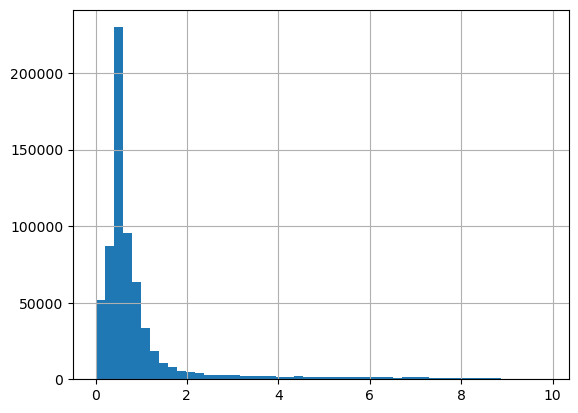

In [71]:
df_erros_teste_filtrado['Erro_Absoluto'].hist(bins=50)

Faremos agora a atimização de hiperparâmetros.

In [89]:
pipeline_elastic = Pipeline([
    ('preprocessador', preprocessador),
    ('elasticnet', ElasticNet(
        max_iter=10000,
        random_state=42
    ))
])

param_grid = {
    'elasticnet__alpha': [0.01, 0.1, 1.0, 10.0],
    'elasticnet__l1_ratio': [0.2, 0.5, 0.8]
}

grid_search_2 = GridSearchCV(
    estimator=pipeline_elastic,
    param_grid=param_grid,
    cv=3,
    scoring='neg_mean_absolute_error',
    n_jobs=1,
    verbose=1
)

grid_search_2.fit(X_train_filtrado, y_train_filtrado.squeeze())

print('Melhores hiperparâmetros:')
print(grid_search_2.best_params_)

print('\nMelhor MAE na validação cruzada:')
print(-grid_search_2.best_score_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Melhores hiperparâmetros:
{'elasticnet__alpha': 0.1, 'elasticnet__l1_ratio': 0.2}

Melhor MAE na validação cruzada:
0.8055467867907753


In [90]:
# Modelo final com os melhores hiperparâmetros
modelo_otimizado_2 = grid_search_2.best_estimator_

In [91]:
# Previsões no treino filtrado
y_pred_treino_2 = modelo_otimizado_2.predict(X_train_filtrado)

# Métricas no treino filtrado
mae_treino = mean_absolute_error(
    y_train_filtrado.squeeze(), y_pred_treino_2
)
rmse_treino = np.sqrt(mean_squared_error(
    y_train_filtrado.squeeze(), y_pred_treino_2
))
r2_treino = r2_score(
    y_train_filtrado.squeeze(), y_pred_treino_2
)

print('Métricas — Treino filtrado')
print(f'MAE:  {mae_treino:.4f}')
print(f'RMSE: {rmse_treino:.4f}')
print(f'R²:   {r2_treino:.4f}')


# Filtrar o conjunto de teste usando o limite calculado no treino
mascara_teste = y_test <= limite_superior

X_teste_filtrado = X_test.loc[mascara_teste].copy()
y_teste_filtrado = y_test.loc[mascara_teste].copy()

# Previsões no teste filtrado
y_pred_teste_2 = modelo_otimizado_2.predict(X_teste_filtrado)

# Métricas no teste filtrado
mae_teste = mean_absolute_error(
    y_teste_filtrado.squeeze(), y_pred_teste_2
)
rmse_teste = np.sqrt(mean_squared_error(
    y_teste_filtrado.squeeze(), y_pred_teste_2
))
r2_teste = r2_score(
    y_teste_filtrado.squeeze(), y_pred_teste_2
)

print('\nMétricas — Teste filtrado')
print(f'MAE:  {mae_teste:.4f}')
print(f'RMSE: {rmse_teste:.4f}')
print(f'R²:   {r2_teste:.4f}')


# Previsões no teste completo
y_pred_teste_v2 = modelo_otimizado_2.predict(X_test)

# Avaliação no teste completo
print('\nMétricas — Teste completo')
print(f'MAE:  {mean_absolute_error(y_test.squeeze(), y_pred_teste_v2):.4f}')
print(f'RMSE: {np.sqrt(mean_squared_error(y_test.squeeze(), y_pred_teste_v2)):.4f}')
print(f'R²:   {r2_score(y_test.squeeze(), y_pred_teste_v2):.4f}')



print(f'\nObservações no treino filtrado: {len(y_train_filtrado)}')
print(f'Observações no teste filtrado: {len(y_teste_filtrado)}')

Métricas — Treino filtrado
MAE:  0.8055
RMSE: 1.1664
R²:   0.8587

Métricas — Teste filtrado
MAE:  0.8053
RMSE: 1.1674
R²:   0.8584

Métricas — Teste completo
MAE:  5.8246
RMSE: 29.2326
R²:   0.1355

Observações no treino filtrado: 2659134
Observações no teste filtrado: 664896


**1. Comparação das métricas**

| Métrica | Treino filtrado | Teste filtrado | Teste completo |
|---|---:|---:|---:|
| MAE | 0,8056 | 0,8053 | 5,8258 |
| RMSE | 1,1656 | 1,1666 | 29,2495 |
| $R^2$ | 0,8589 | 0,8586 | 0,1345 |

**2. Interpretação dos resultados**

- **Boa generalização na faixa filtrada:** as métricas de treino e teste filtrados são praticamente idênticas. O MAE de aproximadamente 0,81 estudante indica erros absolutos médios inferiores a um estudante nessa faixa. O modelo explica cerca de 85,9% da variabilidade da variável-alvo no teste filtrado.

- **Impacto dos valores extremos:** no teste completo, o MAE aumenta para 5,83 e o RMSE chega a 29,25. Essa diferença expressiva sugere que algumas observações produzem erros muito elevados, que influenciam especialmente o RMSE.

- **Limitação na população completa:** o $R^2$ de 0,1345 no teste completo indica que o modelo tem capacidade explicativa limitada quando são incluídas todas as observações, inclusive aquelas acima do limite utilizado no treinamento.

**3. Conclusão**

A otimização de hiperparâmetros produziu um modelo com desempenho consistente e promissor para as observações abaixo do limite estabelecido pelo quantil. A proximidade das métricas de treino e teste filtrados sugere que não há evidência de sobreajuste relevante nessa faixa. Entretanto, o desempenho no teste completo mostra que o modelo não representa adequadamente toda a distribuição de `QT_SIT_DESVINCULADO`, sobretudo os casos extremos.

## 5. Salvando o modelo

In [92]:
# Salvar o modelo na pasta atual do notebook
joblib.dump(modelo_otimizado_2, 'modelo_quantil_elasticnet_otimizado.pkl')

print('Modelo salvo com sucesso!')

Modelo salvo com sucesso!


In [85]:
%reload_ext watermark
%watermark -a "Mauricio Vinhote"

Author: Mauricio Vinhote



In [62]:
%watermark -v -m

Python implementation: CPython
Python version       : 3.12.7
IPython version      : 8.27.0

Compiler    : MSC v.1929 64 bit (AMD64)
OS          : Windows
Release     : 11
Machine     : AMD64
Processor   : Intel64 Family 6 Model 154 Stepping 3, GenuineIntel
CPU cores   : 12
Architecture: 64bit



In [63]:
%watermark --iversions

numpy  : 1.26.4
pandas : 2.2.2
sklearn: 1.5.1

